Emma - Oct 14

Example code to quickly look at PUMA waveforms taken on the CAEN dt through WaveDump

In [11]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.optimize import curve_fit
import PUMA_signal as PMV
import scipy as sp
from datetime import datetime, timedelta

# functions

In [3]:
def flush_event(adc, dac_value, trigger_ts, event_number):
        """Convert stored ADC samples into an event dict."""
        if len(adc) == 0:
            return None

        adc_arr = np.array(adc, dtype=np.int16)

        # ADC → volts → mV
        volts = (adc_arr - 8192) / 8192.0
        amp_mV = volts * 1000.0

        # DAC baseline correction
        if dac_value is not None:
            baseline_V = (dac_value - 0x8000) / 0x8000
            amp_mV -= baseline_V * 1000.0

        # Trigger timestamp → seconds
        trigger_time_s = trigger_ts * 8e-9  # 8 ns ticks
        trigger_time_us = trigger_time_s * 1e6

        # Sample times
        dt_s = 4e-9  # 4 ns
        time_s = np.arange(len(adc_arr)) * dt_s
        time_us = time_s * 1e6

        # Absolute datetime
        # base_dt = boot_time + timedelta(seconds=trigger_time_s)
        # datetimes = np.array([base_dt + timedelta(seconds=t) for t in time_s])

        return {
            'event_number': event_number,
            'trigger_time_us': trigger_time_us,
            # 'datetime': datetimes,
            'time_us': time_us,
            'amp_mV': amp_mV
        }

    
def loadWF(filename):

    """
    Parse a WaveDump ASCII file containing multiple events.
    
    """

    events = []
    time = []
    voltage_raw = []

    # Temporary storage for current event
    adc = []
    dac_value = None
    trigger_ts = None
    event_number = None

    with open(filename, "r") as f:
        for line in f:
            line = line.strip()

            # Detect new event header
            if line.startswith("Record Length:"):
                # Flush previous event
                evt = flush_event(adc, dac_value, trigger_ts, event_number)
                
                if evt is not None:
                    events.append(evt)
                    time.append(evt["time_us"])
                    voltage_raw.append(evt["amp_mV"])

                # Reset for new event
                adc = []
                dac_value = None
                trigger_ts = None
                event_number = None
                continue

            # Parse header fields
            if line.startswith("Event Number:"):
                event_number = int(line.split(":")[1].strip())
                continue

            if line.startswith("DC offset (DAC):"):
                dac_value = int(line.split(":")[1].strip(), 16)
                continue

            if line.startswith("Trigger Time Stamp:"):
                trigger_ts = int(line.split(":")[1].strip())
                continue

            # Skip other header lines
            if ":" in line or not line:
                continue

            # ADC sample
            try:
                adc.append(int(line))
            except ValueError:
                continue

    # Flush last event
    evt = flush_event(adc, dac_value, trigger_ts, event_number)
    if evt is not None:
        events.append(evt)
        time.append(evt["time_us"])
        voltage_raw.append(evt["amp_mV"])

    return time, voltage_raw

In [9]:
ch1_TImpedance = 213 #kOhm # was prev 223?
ch2_TImpedance = 207 #kOhm # was prev 216?

# drift regions
d2 = 3.88 #cm
d1 = d3 = 0.16 #cm
dtotal_averaged = d2 + (d1+d3)/2

def ProcessDataset_Wavedump(path, filename, Ped = [0, 3000], cut_for_integral=True, cutForSignal=True, 
                      anodeShift=False, reversed=False, ChargeError=False):

    # NDatapoints = len(fileArray)
    # nFlashes = int(NDatapoints/2)

    timing_Ch1, voltageCh1_raw = loadWF(f"{folder_path}{filename}_ch0.txt")
    timing_Ch2, voltageCh2_raw = loadWF(f"{folder_path}{filename}_ch1.txt")
    
    nFlashes = len(voltageCh1_raw)

    # try:
    voltageCh1_raw = np.array(voltageCh1_raw)
    voltageCh2_raw = np.array(voltageCh2_raw)
    timing = np.array(timing_Ch1)
    #     # time_interval = np.array(time_interval)
    # except:
    #     print("Arrays are different lengths")
    are_identical = np.all(timing == timing[0, :])
    sameLength = np.all(len(voltageCh1_raw) == len(voltageCh2_raw))
    

    if not are_identical and not sameLength:
        print("Timing arrays are different")
        return None
    else:
        timing = timing[0]
        time_interval = timing[1] - timing[0]
        
    #get average signal for each channel
    voltageCh1 = np.mean(voltageCh1_raw, axis=0)
    voltageCh2 = np.mean(voltageCh2_raw, axis=0)

    #and get an error -> standard error on the mean
    # using ddof = 1 not 0 for an unbiased value since I don't know the true mean value
    errCh1 = np.std(voltageCh1_raw, axis=0, ddof=1) / np.sqrt(nFlashes)
    errCh2 = np.std(voltageCh2_raw, axis=0, ddof=1) / np.sqrt(nFlashes)
    
    # Find the pedestal
    pedestalCh1 = PMV.find_pedestal(voltageCh1, start_index=Ped[0], end_index=Ped[1])  # Adjust the range as needed
    pedestalCh2 = PMV.find_pedestal(voltageCh2, start_index=Ped[0], end_index=Ped[1])  # Adjust the range as needed
    
    # Subtract the pedestal
    voltageCh1 = voltageCh1 - pedestalCh1
    voltageCh2 = voltageCh2- pedestalCh2

    if reversed:
        #flipped HV run, so flip the signs for the fitting to work
        voltageCh1 = -voltageCh1
        voltageCh2 = -voltageCh2

    signalStart = 0
    
    if isinstance(cutForSignal, float):
        #I am hardcoding in time where to start the fitting, based on the value (in uS) I give in cutForSignal
        signalStart = int(cutForSignal/time_interval) + np.where(np.isclose(timing, 0))[0][0]
    
    elif cutForSignal:
        #split between the starting noise and the signal

        peaks, properties = sp.signal.find_peaks(voltageCh1, height=np.max(voltageCh1)/3, threshold=None, 
                   prominence=10, rel_height=0.5, distance=5)
        bases = properties["right_bases"]    
        pad = 500
        res = [bases[i] for i in range(len(bases)-1) if bases[i] < (bases[i+1]-pad)]

        try:
            signalStart = res[0]+int(pad/2)
        except:
            try:
                if len(bases) > 1:
                    signalStart = bases[-1]
                
            except:
                signalStart = 0

    if anodeShift !=False:
        if anodeShift == True:
            anodeStart = np.argmax(voltageCh1[signalStart:])*2
        else:
            anodeStart = int(anodeShift/time_interval) + np.where(np.isclose(timing, 0))[0][0]
            # print(anodeShift, anodeStart)
    else:
        anodeStart = signalStart
        
    peakHeightCh1 = np.max(voltageCh1[signalStart:])
    peakHeightCh2 = np.min(voltageCh2[anodeStart:]) #this one is negative, so we want the min

    if cut_for_integral:
        # print("Using only signal region", signalStart)
        # Calculate pulse area -> area under curve - using only area after the signal
        areaCh1 = PMV.calculate_pulse_area(time_interval, voltageCh1[signalStart:]) #mV*us
        areaCh2 = PMV.calculate_pulse_area(time_interval, voltageCh2[anodeStart:]) #mV*us

        if ChargeError:
            # to get errors on an integrated region, I am going to use the bootstrapping method
            N = 1000
            areas1, areas2 = [], []
            for i in range(N):
                BS_Vs1 = np.random.normal(loc=voltageCh1[signalStart:], scale=errCh1[signalStart:])
                BS_areaCh1 = PMV.calculate_pulse_area(time_interval, BS_Vs1) #mV*us
                BS_Vs2 = np.random.normal(loc=voltageCh2[anodeStart:], scale=errCh2[anodeStart:])
                BS_areaCh2 = PMV.calculate_pulse_area(time_interval, BS_Vs2) #mV*us

                areas1.append(BS_areaCh1)
                areas2.append(BS_areaCh2)

    else:
        # Calculate pulse area -> area under curve
        areaCh1 = PMV.calculate_pulse_area(time_interval, voltageCh1) #mV*us
        areaCh2 = PMV.calculate_pulse_area(time_interval, voltageCh2) #mV*us

        if ChargeError:
            # to get errors on an integrated region, I am going to use the bootstrapping method
            N = 1000
            areas1, areas2 = [], []
            for i in range(N):
                BS_Vs1 = np.random.normal(loc=voltageCh1, scale=errCh1)
                BS_areaCh1 = PMV.calculate_pulse_area(time_interval, BS_Vs1) #mV*us
                BS_Vs2 = np.random.normal(loc=voltageCh2, scale=errCh2)
                BS_areaCh2 = PMV.calculate_pulse_area(time_interval, BS_Vs2) #mV*us

                areas1.append(BS_areaCh1)
                areas2.append(BS_areaCh2)
    
    if ChargeError:
        # convert area to charge using calibration for each side
        # Trans-impedance is 213 kOhm for amplifier ch.1 and 207 kOhm for ch.2.
        chargeCh1 = areaCh1 / ch1_TImpedance#resulting in charge in pC
        chargeCh2 = areaCh2 / ch2_TImpedance #resulting in charge in pC

        #and then get the std of the resulting distributions
        areaCh1_std = np.std(areas1)
        areaCh2_std = np.std(areas2)

        chargeCh1_err = areaCh1_std / ch1_TImpedance #resulting in charge in pC
        chargeCh2_err = areaCh2_std / ch2_TImpedance #resulting in charge in pC

        chargeRatio = np.abs(chargeCh2/chargeCh1) 
        chargeRatio_err = chargeRatio*np.sqrt((chargeCh1_err/chargeCh1)**2 + (chargeCh2_err/chargeCh2)**2)

        #package them up
        chargeCh1 = [chargeCh1, chargeCh1_err]
        chargeCh2 = [chargeCh2, chargeCh2_err]
        chargeRatio = [chargeRatio, chargeRatio_err]

    else:
        # convert area to charge using calibration for each side
        # Trans-impedance is 213 kOhm for amplifier ch.1 and 207 kOhm for ch.2.
        chargeCh1 = areaCh1 / ch1_TImpedance #resulting in charge in pC
        chargeCh2 = areaCh2 / ch2_TImpedance #resulting in charge in pC
        
        chargeRatio = np.abs(chargeCh2/chargeCh1)

    return [timing, voltageCh1, voltageCh2, areaCh1, areaCh2, chargeCh1, 
            chargeCh2, chargeRatio, signalStart, anodeStart, errCh1, errCh2]

# look at data

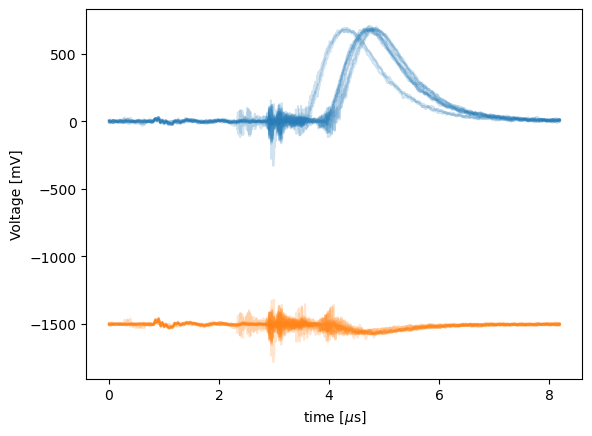

In [12]:
folder_path = "../PUMADAQtesting_data/26-09-03/caen/"
filename = "Multi_realSignal_ch0"

time, voltage_raw = loadWF(f"{folder_path}{filename}.txt")

for i in range(len(time)):
    plt.plot(time[i], voltage_raw[i], alpha=0.2, color="C0")

filename = "Multi_realSignal_ch1"

time, voltage_raw = loadWF(f"{folder_path}{filename}.txt")

for i in range(len(time)):
    plt.plot(time[i], voltage_raw[i], alpha=0.2, color="C1")

# plt.grid()
plt.xlabel("time [$\\mu$s]")
plt.ylabel("Voltage [mV]")
plt.show()

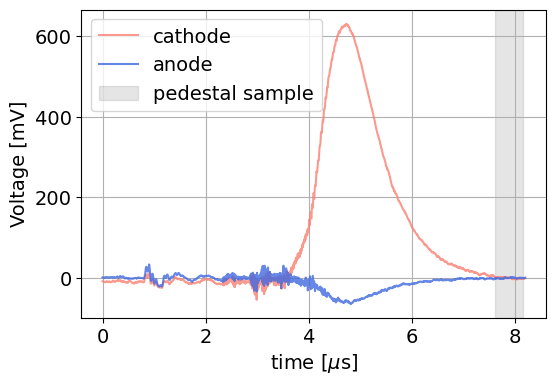

In [33]:
filename = "Multi_realSignal"

startPed = 1900
endPed = 2040

processedSignalData = ProcessDataset_Wavedump(folder_path, filename, Ped = [startPed, endPed], 
                                              cutForSignal=3.0, anodeShift=False)

timing, voltageCh1, voltageCh2, areaCh1, areaCh2, chargeCh1, \
        chargeCh2, chargeRatio, signalStart, anodeStart, errCh1, errCh2 = processedSignalData

#plotting
plt.rcParams.update({'font.size': 14})
fig = plt.figure(figsize=(6, 4))
plt.plot(timing, voltageCh1, label="cathode", color='salmon', alpha=0.8)
plt.plot(timing, voltageCh2, label="anode", color='royalblue', alpha=0.8)
plt.axvspan(timing[startPed], timing[endPed], label="pedestal sample", color='grey', alpha=0.2)
plt.legend()
plt.grid()
plt.xlabel("time [$\\mu$s]")
plt.ylabel("Voltage [mV]")
plt.show()

In [34]:
#full waveform analysis
Ch1Max_time, Ch2Min_time, chargeRatio_fit, DeltaT, Vdr, \
    eLifetime_fit, fitData_cath, fitData_anode, \
    chargeCh1_fit, chargeCh2_fit, AnalysisStats = PMV.AnalysisDataset_fit_err(processedSignalData)

Ch1Max_index, Ch2Min_index, DeltaTime, Vdr, eLifetime = AnalysisStats

VoltagePeaks_data = PMV.GetVoltagePeaks_data(processedSignalData, AnalysisStats)
ch1Max, ch1Max_err, ch2Min, ch2Min_err= VoltagePeaks_data

print(f"DeltaTime = {DeltaTime} uS, Vdr={Vdr} cm/s")
print(ch1Max, ch1Max_err,)

DeltaTime = 0.08799999999999919 uS, Vdr=45909090.90909133 cm/s
630.8346255794986 21.585435069569552


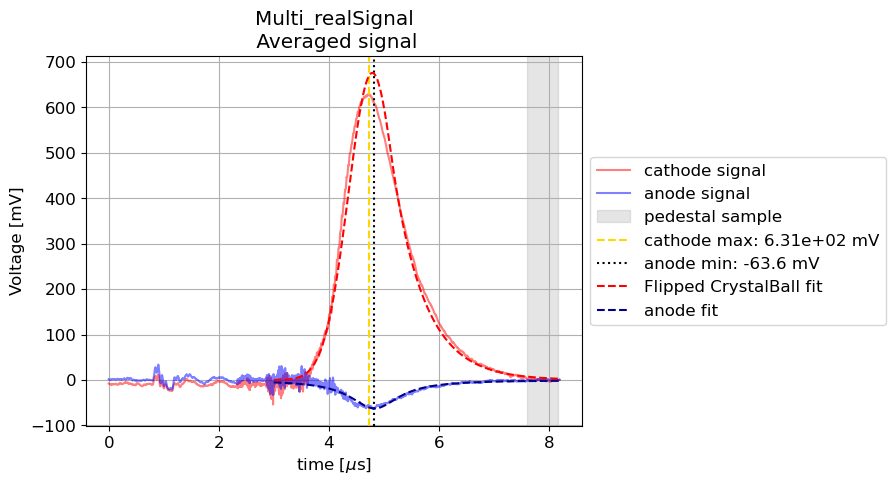

In [36]:
plt.rcParams.update({'font.size': 12})

plt.plot(timing, voltageCh1, color='red', label="cathode signal", alpha=0.5)
plt.plot(timing, voltageCh2, color='blue', label="anode signal", alpha=0.5)

plt.axvspan(timing[startPed], timing[endPed], label="pedestal sample", color='grey', alpha=0.2)
plt.axvline(timing[signalStart+Ch1Max_index], ls="--", color="gold", 
            label=f"cathode max: {voltageCh1[signalStart:][Ch1Max_index]:.3} mV")

plt.axvline(timing[anodeStart+Ch2Min_index], color='black', ls=":", 
            label=f"anode min: {voltageCh2[anodeStart:][Ch2Min_index]:.3} mV")

# print(fitData_cath)
# C, alpha, N, sigma, mean
plt.plot(timing[signalStart:], PMV.CrystalBall_funct(timing[signalStart:], fitData_cath['C'], 
            fitData_cath['alpha'],fitData_cath['N'],fitData_cath['sigma'],fitData_cath['mean']), 
            color='red', label="Flipped CrystalBall fit", ls="--")

plt.plot(timing[anodeStart:], PMV.lorentzian(timing[anodeStart:], fitData_anode['A'], 
            fitData_anode['x0'], fitData_anode['gamma']), color='darkblue', label="anode fit", ls="--")

plt.xlabel("time [$\\mu$s]")
plt.ylabel("Voltage [mV]")
plt.grid()
# plt.legend()
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.title(f"{filename}\n Averaged signal")

# plt.savefig(f"{folder_path}/{filename}_fit.pdf", bbox_inches='tight')
plt.show()